In [68]:
import pandas as pd

df = pd.read_csv('/content/drug200.csv')

# Display first 5 rows
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


In [69]:
df['Drug'].unique()

array(['DrugY', 'drugC', 'drugX', 'drugA', 'drugB'], dtype=object)

In [70]:
drug_map = {
    'DrugY': 0,
    'drugC': 1,
    'drugX': 2,
    'drugA': 3,
    'drugB': 4
}

df['Drug'] = df['Drug'].map(drug_map)

In [71]:
print(df['Drug'].unique())

[0 1 2 3 4]


In [72]:
# Display unique values in all columns

for col in df.columns:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in Age:
[23 47 28 61 22 49 41 60 43 34 74 50 16 69 32 57 63 48 33 31 39 45 18 65
 53 46 15 73 58 66 37 68 67 62 24 26 40 38 29 17 54 70 36 19 64 59 51 42
 56 20 72 35 52 55 30 21 25]

Unique values in Sex:
['F' 'M']

Unique values in BP:
['HIGH' 'LOW' 'NORMAL']

Unique values in Cholesterol:
['HIGH' 'NORMAL']

Unique values in Na_to_K:
[25.355 13.093 10.114  7.798 18.043  8.607 16.275 11.037 15.171 19.368
 11.767 19.199 15.376 20.942 12.703 15.516 11.455 13.972  7.298 25.974
 19.128 25.917 30.568 15.036 33.486 18.809 30.366  9.381 22.697 17.951
  8.75   9.567 11.014 31.876 14.133  7.285  9.445 13.938  9.709  9.084
 19.221 14.239 15.79  12.26  12.295  8.107 13.091 10.291 31.686 19.796
 19.416 10.898 27.183 18.457 10.189 14.16  11.34  27.826 10.091 18.703
 29.875  9.475 20.693  8.37  13.303 27.05  12.856 10.832 24.658 24.276
 13.967 19.675 10.605 22.905 17.069 20.909 11.198 19.161 13.313 10.84
 13.934  7.761  9.712 11.326 10.067 13.935 13.597 15.478 23.091 17.211
 16.594 1

In [73]:
# Missing values in each column
df.isnull().sum()

,0
Age,0
Sex,0
BP,0
Cholesterol,0
Na_to_K,0
Drug,0


In [74]:
# Total duplicate rows
df.duplicated().sum()

np.int64(0)

In [75]:
# Skewness of numerical columns
df.skew(numeric_only=True)

,0
Age,0.030308
Na_to_K,1.039341
Drug,0.536941


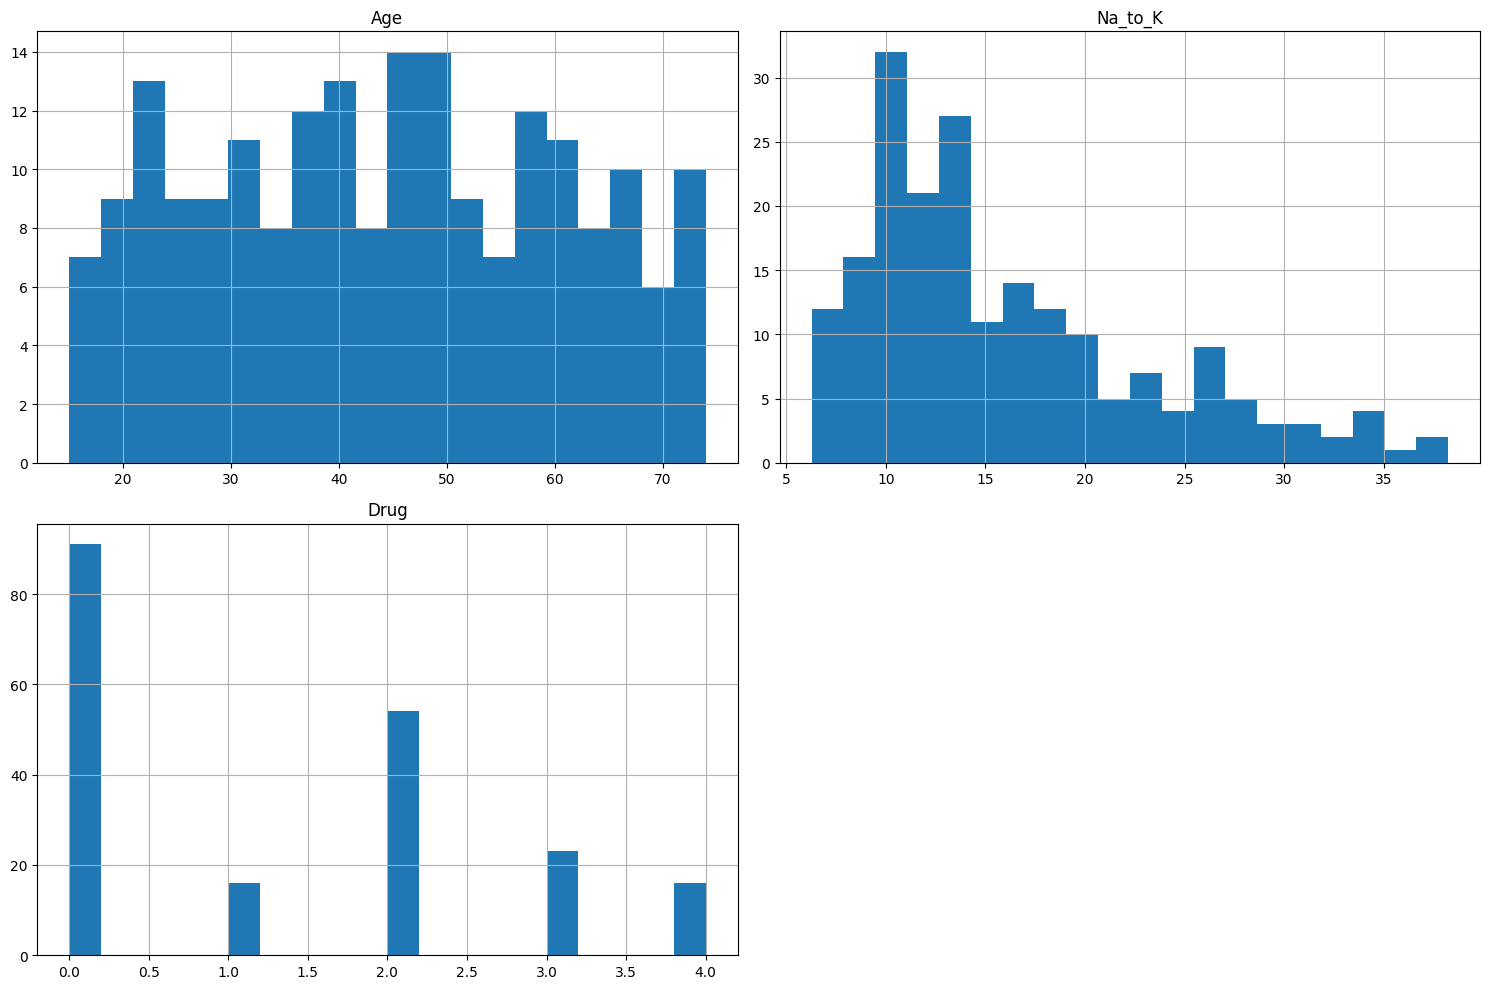

In [76]:
import matplotlib.pyplot as plt

df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

In [77]:
# Select numerical columns
num_cols = df.select_dtypes(include='number').columns

# Calculate Q1 and Q3
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Count outliers in each column
outliers = ((df[num_cols] < lower) | (df[num_cols] > upper)).sum()

print(outliers)

Age        0
Na_to_K    8
Drug       0
dtype: int64


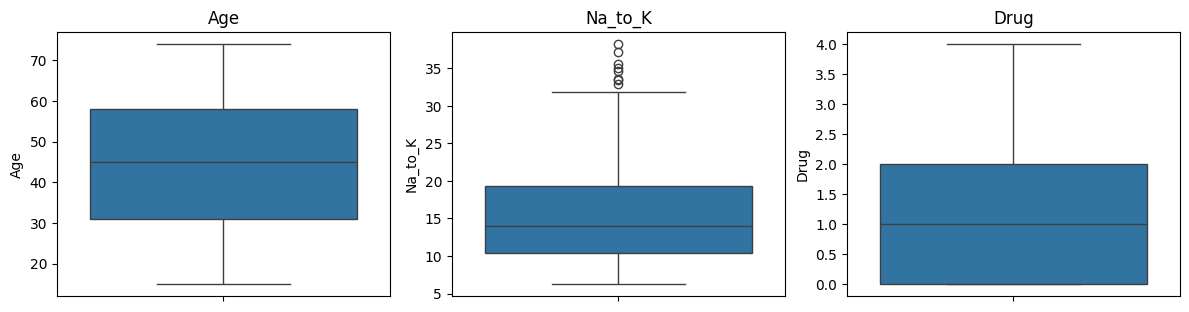

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(12, 6))

for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [79]:
# Select numerical columns
num_cols = df.select_dtypes(include='number').columns

# Calculate Q1 and Q3
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Cap outliers
df[num_cols] = df[num_cols].clip(lower=lower, upper=upper, axis=1)

In [80]:
# Check remaining outliers
outliers_after = (
    (df[num_cols] < lower) | (df[num_cols] > upper)
).sum()

print(outliers_after)

Age        0
Na_to_K    0
Drug       0
dtype: int64


In [81]:
# Numerical columns
num_cols = df.select_dtypes(include='number').columns

# Categorical columns
cat_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

Numerical Columns: ['Age', 'Na_to_K', 'Drug']
Categorical Columns: ['Sex', 'BP', 'Cholesterol']


In [82]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

X = df.drop(columns=['Drug'])
y = df['Drug']

# ==========================================
# 4. Identify Numerical and Categorical Columns
# ==========================================

num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

# ==========================================
# 5. Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# 6. Numerical Pipeline
# ==========================================

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# ==========================================
# 7. Categorical Pipeline
# ==========================================

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# ==========================================
# 8. Column Transformer
# ==========================================

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols)
])

# ==========================================
# 9. Complete ML Pipeline
# ==========================================

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# ==========================================
# 10. Train Model
# ==========================================

model.fit(X_train, y_train)

# ==========================================
# 11. Predictions
# ==========================================

y_pred = model.predict(X_test)

# ==========================================
# 12. Model Evaluation
# ==========================================

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ==========================================
# 13. Test with New Patient Data
# ==========================================

new_patient = pd.DataFrame({
    'Age': [35],
    'Sex': ['M'],
    'BP': ['HIGH'],
    'Cholesterol': ['NORMAL'],
    'Na_to_K': [15.5]
})

prediction = model.predict(new_patient)

print("\nPredicted Drug:", prediction[0])

Numerical Columns: ['Age', 'Na_to_K']
Categorical Columns: ['Sex', 'BP', 'Cholesterol']
Accuracy: 0.925

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95        18
           1       1.00      1.00      1.00         3
           2       1.00      0.91      0.95        11
           3       0.83      1.00      0.91         5
           4       1.00      0.33      0.50         3

    accuracy                           0.93        40
   macro avg       0.95      0.85      0.86        40
weighted avg       0.93      0.93      0.91        40


Confusion Matrix:
[[18  0  0  0  0]
 [ 0  3  0  0  0]
 [ 1  0 10  0  0]
 [ 0  0  0  5  0]
 [ 1  0  0  1  1]]

Predicted Drug: 0


In [83]:
import pandas as pd

new_patient = pd.DataFrame({
    'Age': [35],
    'Sex': ['F'],
    'BP': ['LOW'],
    'Cholesterol': ['NORMAL'],
    'Na_to_K': [15.5]
})

prediction = model.predict(new_patient)

print("Predicted Drug:", prediction[0])

Predicted Drug: 2


In [84]:
!pip install joblib


import joblib

# Save complete ML pipeline
joblib.dump(model, 'drug_prediction_model.pkl')

print("Model saved successfully!")


from IPython.display import FileLink

FileLink('drug_prediction_model.pkl')

Model saved successfully!


/content/drug_prediction_model.pkl

import joblib

# Load trained model
model = joblib.load('drug_prediction_model.pkl')

print("Model loaded successfully!")